<a href="https://colab.research.google.com/github/tlh222k/aio/blob/main/M4/foundational-deep-learning/01-linear-regression/code/01-optimize-sphere-1D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TỐI ƯU HÓA HÀM SPHERE 1D BẰNG GRADIENT DESCENT**

Notebook này minh họa các khái niệm nền tảng nhất của toán tối ưu và học máy thông qua việc tối ưu hóa **hàm Sphere trong không gian 1 chiều (1D)** sử dụng thuật toán **Gradient Descent**.

## **1. Hàm số mục tiêu (Objective Function): Hàm Sphere 1D**

Trong tối ưu hóa toán học, **hàm Sphere** là một hàm kiểm thử chuẩn (benchmark function) thường dùng để đánh giá hiệu năng của các thuật toán tối ưu.

* **Công thức tổng quát** trong không gian $n$-chiều:
  $$f(x) = \sum_{i=1}^{n} x_i^2$$
* **Trong không gian 1 chiều (1D)**, hàm số này trở thành hàm Parabol đơn giản:
  $$f(x) = x^2$$

> **Mục tiêu:** Tìm giá trị tối ưu của $x$ sao cho $f(x)$ đạt giá trị nhỏ nhất (**Global Minimum**). Bằng trực giác toán học, cực tiểu đạt được tại $x = 0$ với $f(0) = 0$.

## **2. Đạo hàm và Gradient (Derivative & Gradient)**

Để tìm đường đi ngắn nhất đến điểm cực tiểu mà không cần thử mọi giá trị của $x$, chúng ta sử dụng công cụ đạo hàm:

* **Đạo hàm** của hàm số $f(x) = x^2$ theo biến $x$ là:
  $$f'(x) = 2x$$
* **Ý nghĩa lý thuyết:** Đạo hàm $f'(x)$ cho biết độ dốc (slope) và hướng tăng nhanh nhất của hàm số tại điểm $x$ hiện tại.

### **2.1. Trực quan hóa: Tại sao cần Đạo hàm để tối ưu?**

Hãy tưởng tượng bạn đang bị bịt mắt và đứng trên một đỉnh núi sương mù dày đặc. Nhiệm vụ của bạn là phải tìm đường xuống thung lũng (điểm thấp nhất). Bạn không thể nhìn thấy toàn cảnh bản đồ, vậy bạn sẽ làm thế nào?

Khi bị bịt mắt, cách duy nhất bạn có thể làm là dùng chân để cảm nhận mặt đất xung quanh mình:

1. **Xác định hướng đi:**
   * Nếu bạn cảm nhận hướng bên phải dốc lên cao nhất, thì hiển nhiên hướng ngược lại (bên trái) sẽ là hướng đi xuống dốc.
   * **Đạo hàm chính là hướng dốc:**
     * Nếu đạo hàm $f'(x) > 0$ (mang dấu dương): Hàm số đang **tăng** khi đi từ trái sang phải. Để giảm hàm số, ta phải dịch chuyển $x$ sang **trái** (giảm $x$).
     * Nếu đạo hàm $f'(x) < 0$ (mang dấu âm): Hàm số đang **giảm** khi đi từ trái sang phải. Để tiếp tục giảm hàm số, ta phải dịch chuyển $x$ sang **phải** (tăng $x$).
     * Công thức cập nhật $x_{mới} = x_{cũ} - lr \times f'(x)$ tự động làm điều này nhờ dấu trừ ($-$) toán học!

2. **Xác định độ lớn bước đi (Độ dốc):**
   * Nếu mặt đất dưới chân rất dốc, chứng tỏ bạn còn ở xa đáy thung lũng $\rightarrow$ bạn nên bước những bước lớn dứt khoát.
   * Nếu mặt đất bắt đầu thoai thoải (gần như phẳng), chứng tỏ bạn đã rất gần đáy thung lũng $\rightarrow$ bạn nên bước những bước nhỏ, cẩn thận để không bước hụt qua sườn dốc bên kia.
   * Giá trị tuyệt đối của đạo hàm $|f'(x)|$ càng lớn thì đồ thị càng dốc. Nhờ nhân Hệ số học ($lr$) với đạo hàm, bước nhảy của chúng ta tự động **lớn khi ở xa** và tự động **nhỏ lại khi ở gần đáy**.

3. **Điều kiện dừng (Điểm tối ưu):**
   * Khi bạn đã đứng ngay tại đáy thung lũng phẳng lặng, mặt đất dưới chân sẽ hoàn toàn nằm ngang, nghĩa là **độ dốc bằng 0**.
   * Trong toán học, tại điểm cực trị (cực tiểu), đạo hàm của hàm số luôn bằng 0 ($f'(x) = 0$). Lúc này $x_{mới} = x_{cũ} - 0 = x_{cũ}$, thuật toán sẽ hội tụ và dừng lại.

## **3. Thuật toán Gradient Descent (Cực tiểu hóa Gradient)**

Gradient Descent hoạt động theo nguyên lý dịch chuyển ngược hướng với đạo hàm để đi xuống đáy dốc:

1. **Khởi tạo:** Chọn ngẫu nhiên một điểm bắt đầu $x_0$ (ví dụ: một số ngẫu nhiên trong khoảng $[-100, 100]$).
2. **Vòng lặp cập nhật:** Tại mỗi bước $t$, ta cập nhật vị trí mới của $x$ theo công thức:
   $$x_{t+1} = x_t - lr \times f'(x_t)$$

Trong đó:
* $f'(x_t) = 2x_t$ là đạo hàm tại vị trí hiện tại.
* Dấu trừ ($-$) đảm bảo chúng ta đang đi ngược hướng đạo hàm để đi xuống dốc.
* $lr$ (**Learning Rate** - Tỷ lệ học): Hệ số điều chỉnh kích thước bước đi. Ở đây chúng ta chọn mức vừa phải là $lr = 0.1$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random

In [ ]:
def sphere_nd(x):
  """
  f(x)=∑i=1nx2i
  x: có thể là list hoặc numpy array
  return: tổng bình phương các phần tử trong x
  """
  # convert list to numpy array
  x = np.array(x)

  result = sum(x**2)
  return result

def derivative_1d(x):
    return 2*x

# # 1D: x = [3]
# print("1D (x = [3]):", sphere_nd([3]))  # 3^2 = 9

# # 2D: x = [3, 4]
# print("2D (x = [3, 4]):", sphere_nd([3, 4]))  # 3^2 + 4^2 = 25

# # 3D: x = [1, 2, 2]
# print("3D (x = [1, 2, 2]):", sphere_nd([1, 2, 2]))  # 1^2 + 2^2 + 2^2 = 9

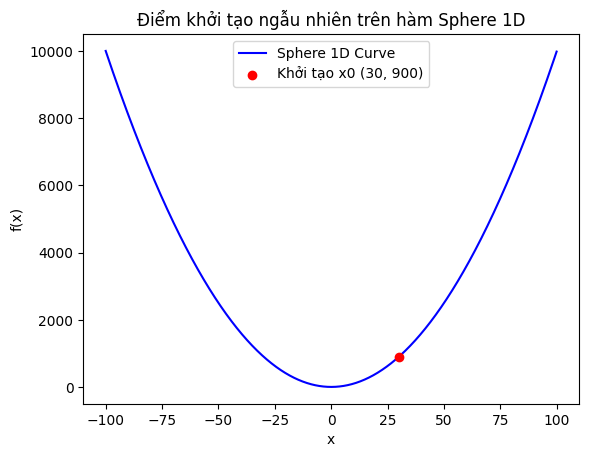

In [ ]:
# 1. Vẽ đường Parabol chuẩn làm nền
x_curve = np.arange(-100, 100, 0.1)
y_curve = np.array([sphere_nd([xi]) for xi in x_curve])
plt.plot(x_curve, y_curve, label="Sphere 1D Curve", color="blue")

# 2. Lấy một điểm x khởi tạo ngẫu nhiên
x_init = random.randint(-100, 100)
# Truyền dưới dạng list [x_init] để hàm sum() trong sphere_nd không bị lỗi
y_init = sphere_nd([x_init])

# 3. Vẽ điểm khởi tạo lên đồ thị
plt.scatter(x_init, y_init, color="red", zorder=5, label=f"Khởi tạo x0 ({x_init}, {y_init})")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Điểm khởi tạo ngẫu nhiên trên hàm Sphere 1D")
plt.legend()
plt.show()

Điểm bắt đầu ngẫu nhiên: x0 = 84.0000, f(x0) = 7056.0000

Quá trình tối ưu hóa:
Bước 01: x = 67.200000, f(x) = 4515.840000
Bước 02: x = 53.760000, f(x) = 2890.137600
Bước 03: x = 43.008000, f(x) = 1849.688064
Bước 04: x = 34.406400, f(x) = 1183.800361
Bước 05: x = 27.525120, f(x) = 757.632231
Bước 06: x = 22.020096, f(x) = 484.884628
Bước 07: x = 17.616077, f(x) = 310.326162
Bước 08: x = 14.092861, f(x) = 198.608744
Bước 09: x = 11.274289, f(x) = 127.109596
Bước 10: x = 9.019431, f(x) = 81.350141


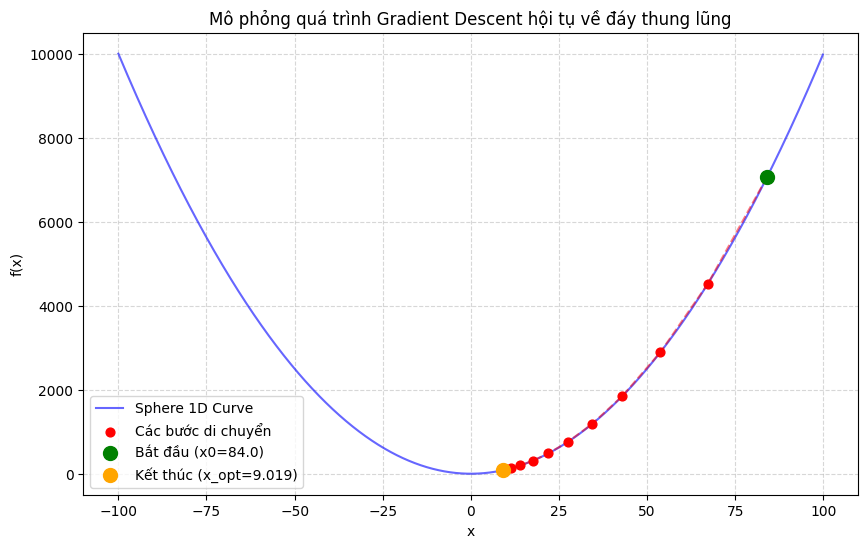

In [ ]:
num_steps = 10
lr = 0.1

# Khởi tạo lại điểm bắt đầu để minh họa đường đi từ đầu
x_current = random.randint(-100, 100)

# Lưu lại lịch sử các bước để vẽ đồ thị
x_history = [x_current]
y_history = [sphere_nd([x_current])]

print(f"Điểm bắt đầu ngẫu nhiên: x0 = {x_current:.4f}, f(x0) = {y_history[0]:.4f}\n")
print("Quá trình tối ưu hóa:")
for step_idx in range(1, num_steps + 1):
    # 1. Tính đạo hàm
    dx = derivative_1d(x_current)

    # 2. Cập nhật vị trí mới
    x_current = x_current - lr * dx
    y_current = sphere_nd([x_current])

    # Lưu lịch sử
    x_history.append(x_current)
    y_history.append(y_current)

    print(f"Bước {step_idx:02d}: x = {x_current:.6f}, f(x) = {y_current:.6f}")

# --- VẼ ĐỒ THỊ MINH HỌA QUÁ TRÌNH DI CHUYỂN ---
plt.figure(figsize=(10, 6))
# Vẽ đường Parabol nền
plt.plot(x_curve, y_curve, label="Sphere 1D Curve", color="blue", alpha=0.6)

# Vẽ toàn bộ quá trình di chuyển của các bước
plt.plot(x_history, y_history, color="red", linestyle="--", alpha=0.5)
plt.scatter(x_history, y_history, color="red", s=40, zorder=5, label="Các bước di chuyển")

# Điểm bắt đầu (màu xanh lá) và điểm kết thúc (màu vàng)
plt.scatter(x_history[0], y_history[0], color="green", s=100, zorder=6, label=f"Bắt đầu (x0={x_history[0]:.1f})")
plt.scatter(x_history[-1], y_history[-1], color="orange", s=100, zorder=6, label=f"Kết thúc (x_opt={x_history[-1]:.3f})")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Mô phỏng quá trình Gradient Descent hội tụ về đáy thung lũng")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()